# 🚗 Nigerian Car Price Prediction
**Dataset:** [Nigerian Car Prices – Kaggle (segunadedipe)](https://www.kaggle.com/datasets/segunadedipe/nigerian-car-prices/data)

This notebook covers the full workflow:

1. **Setup & data loading**
2. **Data understanding** – structure, types, missing values, duplicates
3. **Data cleaning** – type fixes, missing values, invalid values, outliers, rare categories
4. **Exploratory Data Analysis (EDA)** – univariate, bivariate and multivariate analysis, with observations after each step
5. **Feature engineering**
6. **Modelling** – 70% train / **30% test**, 10 regression algorithms compared
7. **Model evaluation & selection** – R², MAE, RMSE, MAPE, cross-validation, tuning of the best model
8. **Interpretation** – feature importance, residual analysis
9. **Summary of insights & recommendations**

> Place `Nigerian_Car_Prices.csv` in the same folder as this notebook (or change `DATA_PATH` below). All prices are in **Nigerian Naira (₦)**.

## 1. Setup

In [1]:
import warnings, re
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBRegressor; HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMRegressor; HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='crest')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
DATA_PATH = 'Nigerian_Car_Prices.csv'

naira = mtick.FuncFormatter(lambda x, _: f'₦{x/1e6:,.0f}M')
print('XGBoost available:', HAS_XGB, '| LightGBM available:', HAS_LGBM)

XGBoost available: True | LightGBM available: True


## 2. Load the data & first look

In [2]:
import os
import pandas as pd
import kagglehub

# Download latest version
path = kagglehub.dataset_download("segunadedipe/nigerian-car-prices")

print("Path to dataset files:", path)

# List the files in the downloaded dataset directory
files = os.listdir(path)
print("Files in dataset directory:", files)

# Find and load the CSV file
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"\nSuccessfully loaded {csv_files[0]} containing {df.shape[0]} rows and {df.shape[1]} columns.")

    # Display first few rows and basic info
    print("\nDataset Information:")
    print(df.info())

    print("\nFirst 5 rows:")
    display(df.head())
else:
    print("No CSV file found in the dataset directory.")

Using Colab cache for faster access to the 'nigerian-car-prices' dataset.
Path to dataset files: /kaggle/input/nigerian-car-prices
Files in dataset directory: ['Nigerian_Car_Prices.csv']

Successfully loaded Nigerian_Car_Prices.csv containing 4095 rows and 10 columns.

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4095 entries, 0 to 4094
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           4095 non-null   int64  
 1   Make                 4095 non-null   object 
 2   Year of manufacture  3617 non-null   float64
 3   Condition            3616 non-null   object 
 4   Mileage              4024 non-null   float64
 5   Engine Size          3584 non-null   float64
 6   Fuel                 3607 non-null   object 
 7   Transmission         4075 non-null   object 
 8   Price                4095 non-null   object 
 9   Build                1127 non-null   object 
dt

,Unnamed: 0,Make,Year of manufacture,Condition,Mileage,Engine Size,Fuel,Transmission,Price,Build
0,0,Toyota,"2,007.00",Nigerian Used,"166,418.00","2,400.00",Petrol,Automatic,"3,120,000",NaN
1,1,Lexus,NaN,NaN,"138,024.00",NaN,NaN,Automatic,"5,834,000",NaN
2,2,Mercedes-Benz,"2,008.00",Nigerian Used,"376,807.00","3,000.00",Petrol,Automatic,"3,640,000",NaN
3,3,Lexus,NaN,NaN,"213,362.00",NaN,NaN,Automatic,"3,594,000",NaN
4,4,Mercedes-Benz,NaN,NaN,"106,199.00",NaN,NaN,Automatic,"8,410,000",NaN


In [3]:
raw = pd.read_csv(csv_path)
print('Shape:', raw.shape)
raw.head(10)

Shape: (4095, 10)


,Unnamed: 0,Make,Year of manufacture,Condition,Mileage,Engine Size,Fuel,Transmission,Price,Build
0,0,Toyota,"2,007.00",Nigerian Used,"166,418.00","2,400.00",Petrol,Automatic,"3,120,000",NaN
1,1,Lexus,NaN,NaN,"138,024.00",NaN,NaN,Automatic,"5,834,000",NaN
2,2,Mercedes-Benz,"2,008.00",Nigerian Used,"376,807.00","3,000.00",Petrol,Automatic,"3,640,000",NaN
3,3,Lexus,NaN,NaN,"213,362.00",NaN,NaN,Automatic,"3,594,000",NaN
4,4,Mercedes-Benz,NaN,NaN,"106,199.00",NaN,NaN,Automatic,"8,410,000",NaN
5,5,Mercedes-Benz,NaN,NaN,"87,660.00",NaN,NaN,Automatic,"5,554,000",NaN
6,6,Lexus,NaN,NaN,"191,411.00",NaN,NaN,Automatic,"3,706,000",NaN
7,7,Lexus,NaN,NaN,"59,092.00",NaN,NaN,Automatic,"8,410,000",NaN
8,8,Mercedes-Benz,NaN,NaN,"89,423.00",NaN,NaN,Automatic,"6,506,000",NaN
9,9,Lexus,NaN,NaN,"184,827.00",NaN,NaN,Automatic,"4,000,000",NaN


In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4095 entries, 0 to 4094
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           4095 non-null   int64  
 1   Make                 4095 non-null   object 
 2   Year of manufacture  3617 non-null   float64
 3   Condition            3616 non-null   object 
 4   Mileage              4024 non-null   float64
 5   Engine Size          3584 non-null   float64
 6   Fuel                 3607 non-null   object 
 7   Transmission         4075 non-null   object 
 8   Price                4095 non-null   object 
 9   Build                1127 non-null   object 
dtypes: float64(3), int64(1), object(6)
memory usage: 320.1+ KB


In [5]:
raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,"4,095.00",NaN,NaN,NaN,"2,047.00","1,182.27",0.00,"1,023.50","2,047.00","3,070.50","4,094.00"
Make,4095,49,Toyota,1469,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year of manufacture,"3,617.00",NaN,NaN,NaN,"2,007.90",4.30,"1,992.00","2,005.00","2,008.00","2,011.00","2,021.00"
Condition,3616,3,Nigerian Used,2521,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mileage,"4,024.00",NaN,NaN,NaN,"182,533.66","210,923.30",1.00,"102,064.00","161,352.50","231,952.25","9,976,050.00"
Engine Size,"3,584.00",NaN,NaN,NaN,"3,274.98","7,693.49",3.00,"2,000.00","2,500.00","3,500.00","371,000.00"
Fuel,3607,4,Petrol,3535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,4075,4,Automatic,3810,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,4095,579,"2,625,000",113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Build,1127,1,SUV,1127,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Missing values & duplicates

,missing,pct_missing
Build,2968,72.48
Engine Size,511,12.48
Fuel,488,11.92
Condition,479,11.70
Year of manufacture,478,11.67
Mileage,71,1.73
Transmission,20,0.49
Unnamed: 0,0,0.00
Make,0,0.00
Price,0,0.00


Exact duplicate rows (ignoring the index column): 879


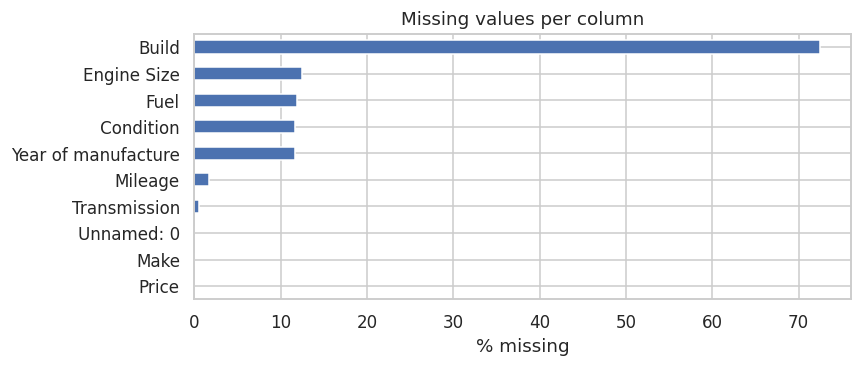

In [6]:
miss = pd.DataFrame({'missing': raw.isna().sum(), 'pct_missing': raw.isna().mean()*100}).sort_values('pct_missing', ascending=False)
display(miss)
print('Exact duplicate rows (ignoring the index column):', raw.drop(columns=[c for c in raw.columns if c.startswith('Unnamed')]).duplicated().sum())

fig, ax = plt.subplots(figsize=(8, 3.5))
miss['pct_missing'].plot.barh(ax=ax, color='#4c72b0')
ax.set_xlabel('% missing'); ax.set_title('Missing values per column'); ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [7]:
for c in raw.select_dtypes('object').columns:
    print(f'\n--- {c} ({raw[c].nunique()} unique) ---')
    print(raw[c].value_counts(dropna=False).head(15).to_string())


--- Make (49 unique) ---
Make
Toyota           1469
Lexus             464
Mercedes-Benz     436
Honda             428
Ford              197
Hyundai           179
Nissan            173
Kia                90
Land Rover         74
Volkswagen         64
Mazda              63
BMW                63
Acura              56
Infiniti           41
Chevrolet          40

--- Condition (3 unique) ---
Condition
Nigerian Used    2521
Foreign Used     1090
NaN               479
Brand New           5

--- Fuel (4 unique) ---
Fuel
Petrol      3535
NaN          488
Diesel        37
Hybrid        30
Electric       5

--- Transmission (4 unique) ---
Transmission
Automatic    3810
Manual        230
CVT            22
NaN            20
AMT            13

--- Price (579 unique) ---
Price
2,625,000    113
1,575,000    109
2,100,000    108
3,150,000     92
3,675,000     69
1,260,000     64
4,200,000     62
1,785,000     61
1,050,000     56
2,600,000     54
1,680,000     53
2,310,000     51
1,365,000     48
1,890

**Observations (data understanding)**
- `Unnamed: 0` is just the saved row index – it carries no information and will be dropped.
- `Price` is stored as **text with thousands separators** (e.g. `"3,120,000"`), so it must be converted to a number before any analysis.
- `Build` (body type) is missing for the large majority of rows (see table above) – too sparse to impute reliably, so it will be dropped.
- The other features have a small share of missing values; because these are core attributes of a listing (year, engine, transmission…), rows missing them are dropped rather than guessed.
- Categorical columns are heavily imbalanced (e.g. a few makes dominate; nearly all cars are Petrol/Automatic). Very rare categories will be grouped so the models don't learn from 1–2 examples.

## 3. Data cleaning

In [8]:
df = raw.copy()

# 1) Drop index & sparse columns
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])
build_missing = df['Build'].isna().mean()*100 if 'Build' in df else 0
df = df.drop(columns=['Build'], errors='ignore')
print(f'Dropped Build ({build_missing:.1f}% missing)')

# 2) Standardise column names
df.columns = [c.strip().replace(' ', '_').lower() for c in df.columns]
df = df.rename(columns={'year_of_manufacture': 'year'})

# 3) Clean text columns
for c in df.select_dtypes('object').columns:
    df[c] = df[c].astype(str).str.strip().replace({'nan': np.nan, '': np.nan})

# 4) Fix numeric types
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
for c in ['year', 'mileage', 'engine_size']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

log = [('Raw rows', len(raw))]
df = df.dropna(); log.append(('After dropping rows with missing values', len(df)))
df = df.drop_duplicates(); log.append(('After dropping duplicates', len(df)))
df['year'] = df['year'].astype(int)
df.head()

Dropped Build (72.5% missing)


,make,year,condition,mileage,engine_size,fuel,transmission,price
0,Toyota,2007,Nigerian Used,"166,418.00","2,400.00",Petrol,Automatic,3120000
2,Mercedes-Benz,2008,Nigerian Used,"376,807.00","3,000.00",Petrol,Automatic,3640000
30,Lexus,2008,Foreign Used,"301,265.00","3,500.00",Petrol,Automatic,4680000
32,Lexus,2011,Nigerian Used,"105,546.00","4,600.00",Petrol,Automatic,14040000
43,Lexus,2011,Foreign Used,"211,917.00","3,500.00",Petrol,Automatic,6968000


### 3.1 Invalid / implausible values
- **Price**: listings with zero or absurdly low prices are data-entry errors.
- **Mileage**: zero/negative mileage on a *used* car is not credible.
- **Engine size**: the field is in **cc**. Real passenger-car engines range roughly 800–8,000 cc; values outside this are typos (e.g. 20000).
- **Condition**: *Brand New* has only a handful of listings – too few to learn from – so it's removed (the model targets the used-car market).

In [9]:
print(df[['price','mileage','engine_size','year']].describe(percentiles=[.01,.05,.5,.95,.99]).T)
print('\nCondition counts:\n', df['condition'].value_counts())

               count         mean          std        min         1%  \
price       2,760.00 4,089,264.98 4,582,456.92 472,500.00 735,000.00   
mileage     2,760.00   192,440.47   239,336.82       1.00   9,748.49   
engine_size 2,760.00     3,172.39     4,920.15       3.00      30.00   
year        2,760.00     2,007.94         4.35   1,992.00   1,998.00   

                      5%          50%           95%           99%  \
price       1,047,125.00 2,899,750.00 10,699,125.00 24,908,500.00   
mileage        47,600.95   168,028.50    376,809.90    499,237.98   
engine_size     1,500.00     2,500.00      4,700.00     20,000.00   
year            2,001.00     2,008.00      2,015.00      2,018.00   

                      max  
price       58,800,000.00  
mileage      9,976,050.00  
engine_size    184,421.00  
year             2,021.00  

Condition counts:
 condition
Nigerian Used    1918
Foreign Used      837
Brand New           5
Name: count, dtype: int64


In [10]:
before = len(df)
df = df[df['price'] > 100_000]                        # below ₦100k is not a real car price
df = df[df['mileage'] > 0]
df = df[df['engine_size'].between(800, 8000)]
cond_counts = df['condition'].value_counts()
df = df[df['condition'].isin(cond_counts[cond_counts >= 30].index)]   # drops 'Brand New' if tiny
log.append(('After removing invalid values', len(df)))
print(f'Removed {before-len(df)} invalid rows')

Removed 114 invalid rows


### 3.2 Price outliers
Car prices are extremely right-skewed (a few luxury cars cost 50–100× an old Corolla), so outliers are judged on **log(price)** using the IQR rule *within each make* – a ₦150M Range Rover is normal, a ₦150M 2005 Corolla is not.

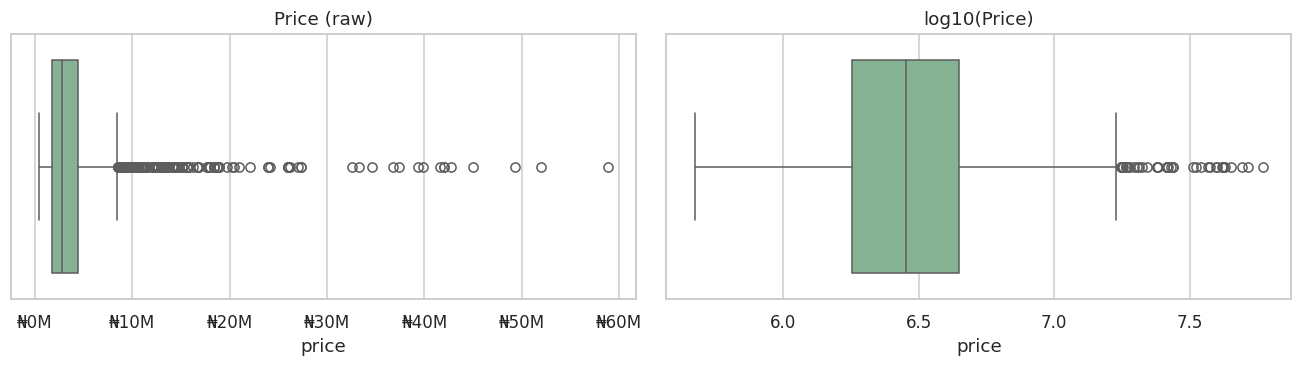

Price outliers flagged: 60 (2.3%)


,make,year,condition,mileage,engine_size,fuel,transmission,price,log_price
377,Mercedes-Benz,2020,Foreign Used,"20,106.00","2,000.00",Petrol,Automatic,58800000,17.89
292,Mercedes-Benz,2018,Foreign Used,"56,263.00","3,000.00",Petrol,Automatic,52000000,17.77
3317,Audi,2019,Nigerian Used,"24,577.00","5,500.00",Petrol,Automatic,49350000,17.71
4058,Toyota,2018,Foreign Used,"64,098.00","2,700.00",Petrol,Automatic,45000000,17.62
3649,Toyota,2020,Foreign Used,"57,656.00","3,500.00",Petrol,Automatic,42750000,17.57
54,Lexus,2016,Nigerian Used,"107,355.00","5,700.00",Petrol,Automatic,42000000,17.55
59,Mercedes-Benz,2017,Nigerian Used,"31,079.00","3,000.00",Petrol,Automatic,41600000,17.54
1732,Toyota,2020,Nigerian Used,"13,668.00","3,500.00",Petrol,Automatic,39900000,17.50
1535,Toyota,2017,Nigerian Used,"8,383.00","4,000.00",Petrol,Automatic,34650000,17.36
247,Mercedes-Benz,2017,Nigerian Used,"33,853.00","3,000.00",Petrol,Automatic,33280000,17.32


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=df['price'], ax=ax[0]); ax[0].xaxis.set_major_formatter(naira); ax[0].set_title('Price (raw)')
sns.boxplot(x=np.log10(df['price']), ax=ax[1]); ax[1].set_title('log10(Price)')
plt.tight_layout(); plt.show()

df['log_price'] = np.log(df['price'])
def iqr_flag(s, k=1.5):
    if len(s) < 10: return pd.Series(False, index=s.index)
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - k*i) | (s > q3 + k*i)
out = df.groupby('make', group_keys=False)['log_price'].apply(iqr_flag)
print(f'Price outliers flagged: {out.sum()} ({out.mean()*100:.1f}%)')
display(df[out].sort_values('price', ascending=False).head(10))
df = df[~out]
log.append(('After removing price outliers', len(df)))

### 3.3 Group rare categories

In [12]:
MIN_COUNT = 15
make_counts = df['make'].value_counts()
rare = make_counts[make_counts < MIN_COUNT].index
print(f'{len(rare)} makes with <{MIN_COUNT} listings grouped as "Other":', list(rare))
df['make'] = df['make'].where(~df['make'].isin(rare), 'Other')

for c in ['fuel', 'transmission']:
    vc = df[c].value_counts()
    small = vc[vc < MIN_COUNT].index
    if len(small): print(f'{c}: grouping {list(small)} as "Other"')
    df[c] = df[c].where(~df[c].isin(small), 'Other')

log.append(('Final clean dataset', len(df)))
clean_log = pd.DataFrame(log, columns=['step', 'rows'])
clean_log['rows_removed'] = -clean_log['rows'].diff().fillna(0).astype(int)
display(clean_log)
print(f'Retained {len(df)/len(raw)*100:.1f}% of the raw rows')

23 makes with <15 listings grouped as "Other": ['Mitsubishi', 'Volvo', 'Dodge', 'Audi', 'Jaguar', 'Opel', 'Jeep', 'Porsche', 'Chrysler', 'Renault', 'Lincoln', 'Skoda', 'Suzuki', 'GMC', 'Mini', 'Changan', 'Seat', 'Hummer', 'MG', 'SsangYong', 'Rover', 'Citroen', 'Daihatsu']
fuel: grouping ['Electric'] as "Other"
transmission: grouping ['AMT'] as "Other"


,step,rows,rows_removed
0,Raw rows,4095,0
1,After dropping rows with missing values,3523,572
2,After dropping duplicates,2760,763
3,After removing invalid values,2646,114
4,After removing price outliers,2586,60
5,Final clean dataset,2586,0


Retained 63.2% of the raw rows


## 4. Feature engineering

In [13]:
REF_YEAR = df['year'].max() + 1          # data was scraped shortly after the newest model year
df['car_age'] = REF_YEAR - df['year']
df['mileage_per_year'] = df['mileage'] / df['car_age'].clip(lower=1)
df['engine_litres'] = (df['engine_size'] / 1000).round(1)
luxury = ['Lexus','Mercedes-Benz','BMW','Land Rover','Audi','Infiniti','Acura','Porsche','Rolls-Royce','Jaguar','Bentley','Volvo']
df['is_luxury'] = df['make'].isin(luxury).astype(int)
print('Reference year:', REF_YEAR)
df.head()

Reference year: 2022


,make,year,condition,mileage,engine_size,fuel,transmission,price,log_price,car_age,mileage_per_year,engine_litres,is_luxury
0,Toyota,2007,Nigerian Used,"166,418.00","2,400.00",Petrol,Automatic,3120000,14.95,15,"11,094.53",2.40,0
2,Mercedes-Benz,2008,Nigerian Used,"376,807.00","3,000.00",Petrol,Automatic,3640000,15.11,14,"26,914.79",3.00,1
30,Lexus,2008,Foreign Used,"301,265.00","3,500.00",Petrol,Automatic,4680000,15.36,14,"21,518.93",3.50,1
32,Lexus,2011,Nigerian Used,"105,546.00","4,600.00",Petrol,Automatic,14040000,16.46,11,"9,595.09",4.60,1
43,Lexus,2011,Foreign Used,"211,917.00","3,500.00",Petrol,Automatic,6968000,15.76,11,"19,265.18",3.50,1


| New feature | Why |
|---|---|
| `car_age` | Depreciation is driven by age; more interpretable than year |
| `mileage_per_year` | Separates heavily-used cars from merely old ones |
| `is_luxury` | Captures the brand premium even for makes grouped into *Other* |
| `log_price` | Target transform – stabilises variance and makes errors proportional |

## 5. Exploratory Data Analysis

### 5.1 Target variable – Price

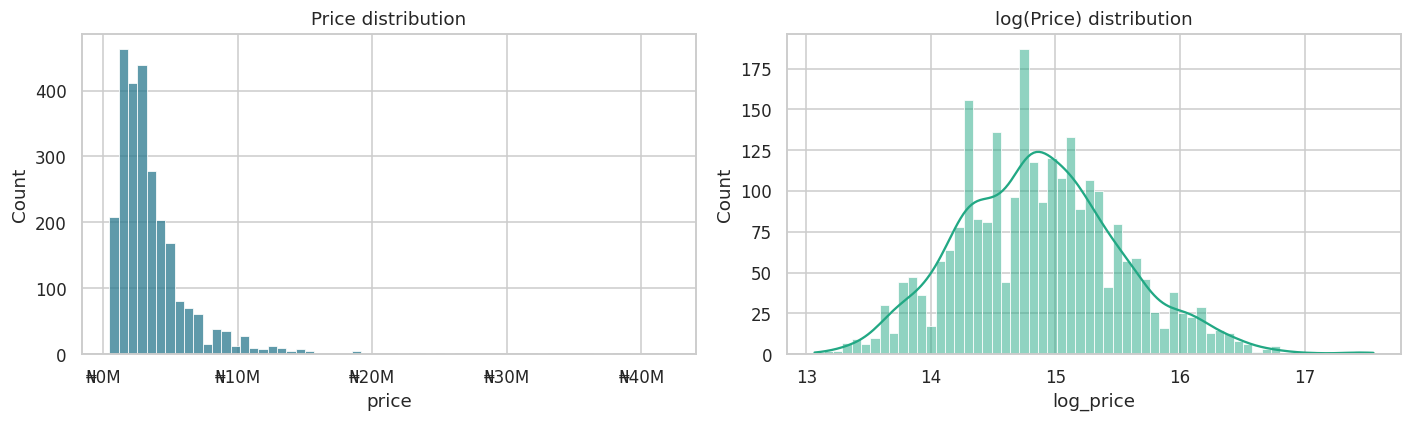

Skewness – price: 4.23 | log price: 0.32
count         ₦2,586
mean      ₦3,634,841
std       ₦3,095,057
min         ₦472,500
25%       ₦1,785,000
50%       ₦2,819,500
75%       ₦4,237,080
max      ₦42,000,000
Name: price, dtype: object


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['price'], bins=60, ax=ax[0], color='#2a788e'); ax[0].xaxis.set_major_formatter(naira); ax[0].set_title('Price distribution')
sns.histplot(df['log_price'], bins=60, kde=True, ax=ax[1], color='#22a884'); ax[1].set_title('log(Price) distribution')
plt.tight_layout(); plt.show()
print(f"Skewness – price: {df['price'].skew():.2f} | log price: {df['log_price'].skew():.2f}")
print(df['price'].describe().apply(lambda v: f'₦{v:,.0f}'))

In [15]:
p = df['price']
print(f'''PRICE INSIGHTS
- Median price ₦{p.median():,.0f} vs mean ₦{p.mean():,.0f} -> mean is pulled up by expensive cars (right skew = {p.skew():.2f}).
- Middle 50% of cars sell between ₦{p.quantile(.25):,.0f} and ₦{p.quantile(.75):,.0f}.
- Top 10% of listings start at ₦{p.quantile(.9):,.0f}.
- Log transform reduces skew to {df["log_price"].skew():.2f}, so models will be trained on log(price).''')

PRICE INSIGHTS
- Median price ₦2,819,500 vs mean ₦3,634,841 -> mean is pulled up by expensive cars (right skew = 4.23).
- Middle 50% of cars sell between ₦1,785,000 and ₦4,237,080.
- Top 10% of listings start at ₦6,760,000.
- Log transform reduces skew to 0.32, so models will be trained on log(price).


### 5.2 Numerical features

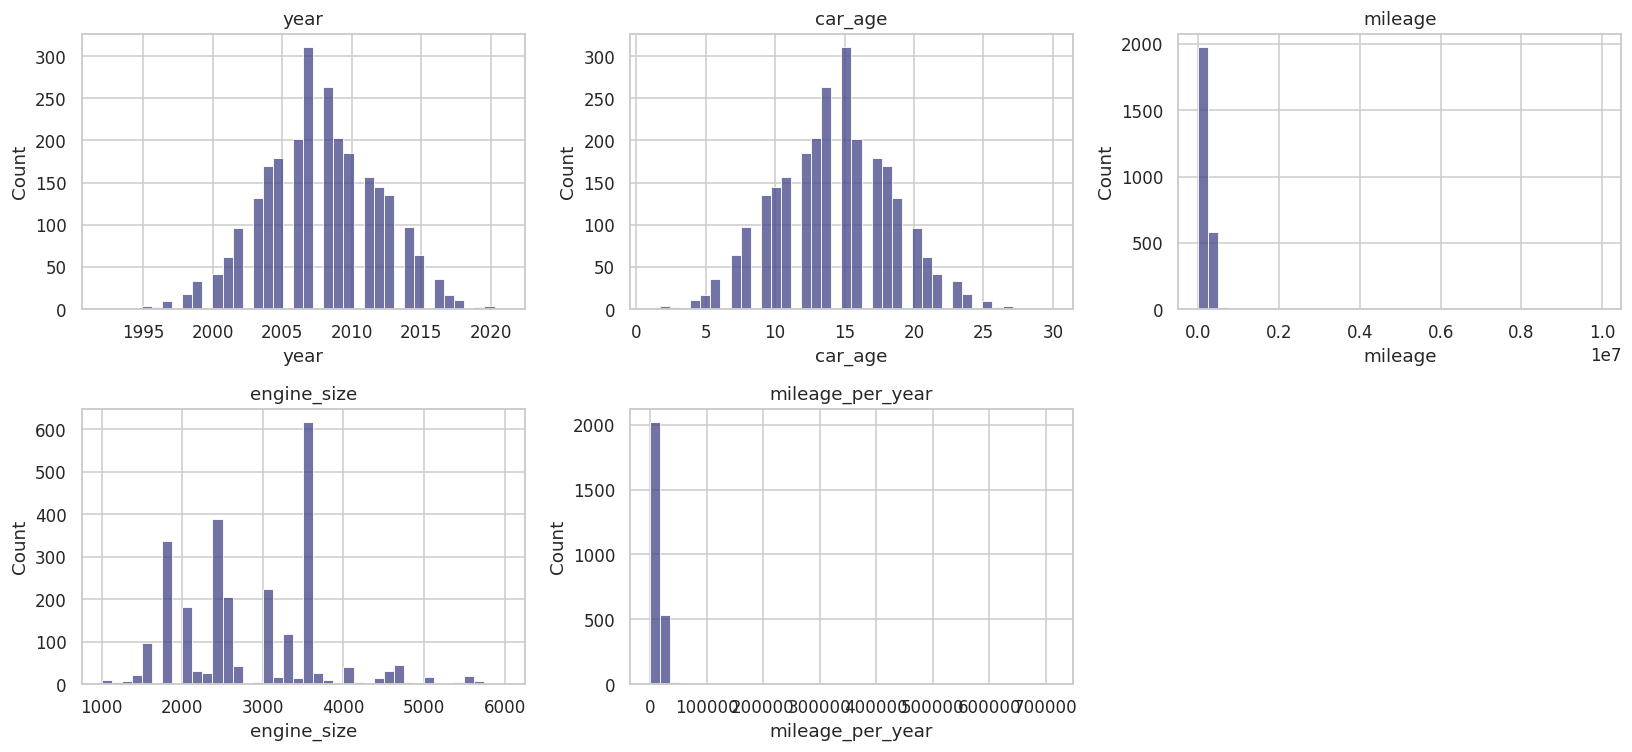

,count,mean,std,min,25%,50%,75%,max
year,"2,586.00","2,007.74",4.20,"1,992.00","2,005.00","2,008.00","2,011.00","2,021.00"
car_age,"2,586.00",14.26,4.20,1.00,11.00,14.00,17.00,30.00
mileage,"2,586.00","196,632.39","245,545.38",1.00,"111,637.00","170,181.50","244,276.00","9,976,050.00"
engine_size,"2,586.00","2,810.10",860.68,"1,000.00","2,000.00","2,500.00","3,500.00","6,000.00"
mileage_per_year,"2,586.00","14,051.84","17,000.74",0.07,"8,770.26","12,249.92","16,857.64","712,575.00"


In [16]:
num = ['year', 'car_age', 'mileage', 'engine_size', 'mileage_per_year']
fig, axes = plt.subplots(2, 3, figsize=(15, 7)); axes = axes.ravel()
for a, c in zip(axes, num):
    sns.histplot(df[c], bins=40, ax=a, color='#414487'); a.set_title(c)
axes[-1].axis('off'); plt.tight_layout(); plt.show()
display(df[num].describe().T)

### 5.3 Categorical features – how common is each?

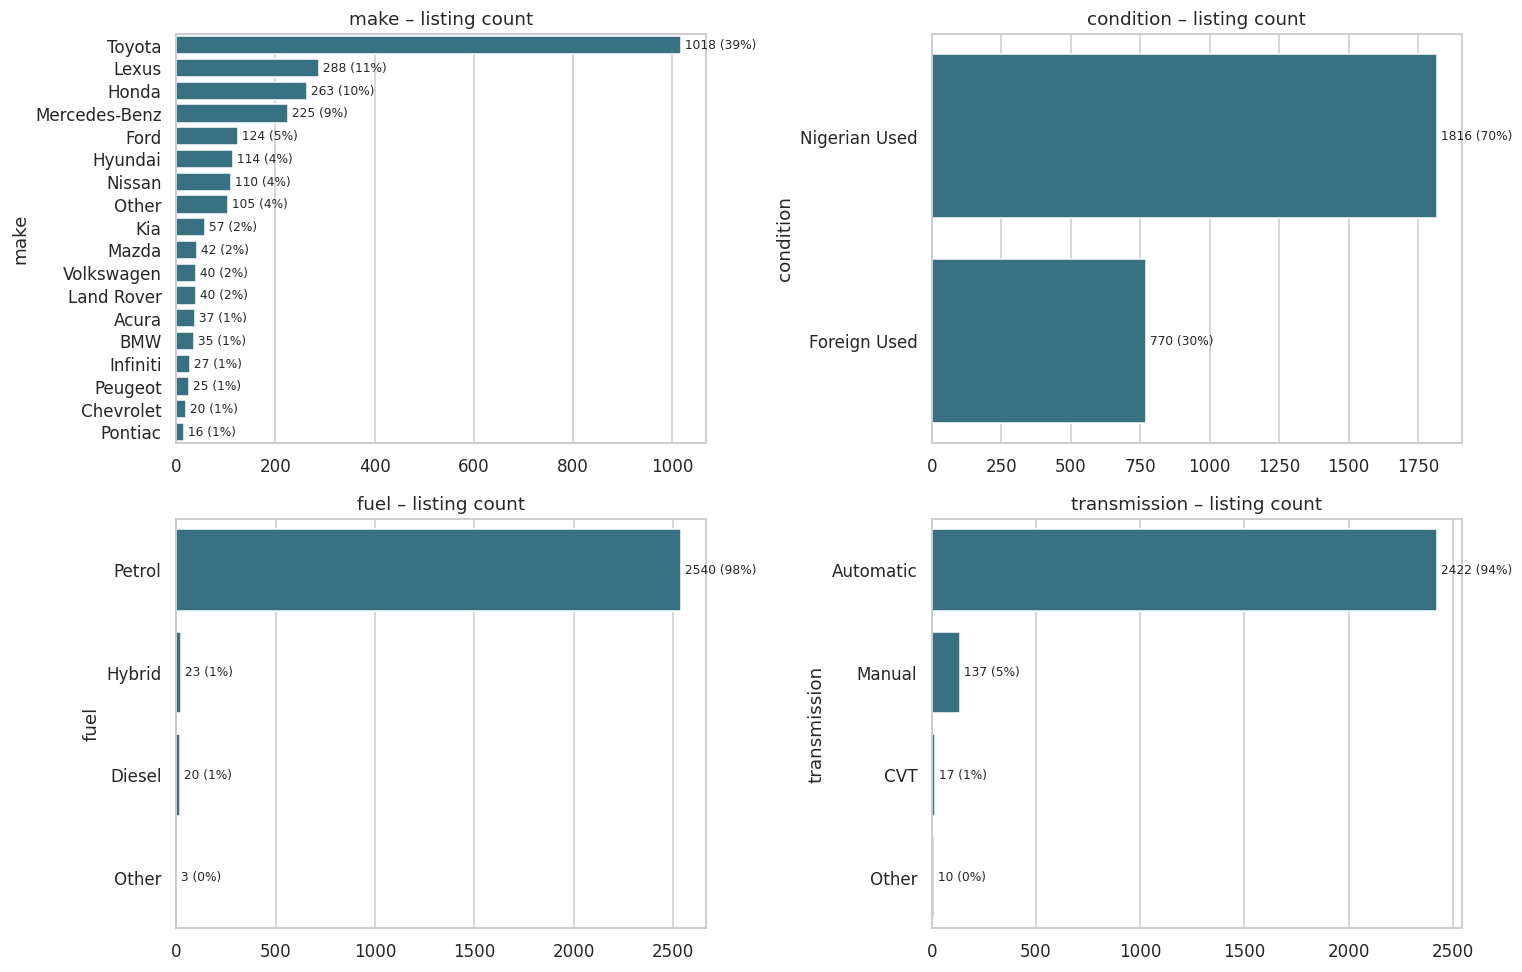

In [17]:
cats = ['make', 'condition', 'fuel', 'transmission']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for a, c in zip(axes.ravel(), cats):
    vc = df[c].value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=a, color='#2a788e')
    for i, v in enumerate(vc.values): a.text(v, i, f' {v} ({v/len(df)*100:.0f}%)', va='center', fontsize=8)
    a.set_title(f'{c} – listing count'); a.set_xlabel('')
plt.tight_layout(); plt.show()

In [18]:
for c in cats:
    vc = df[c].value_counts(normalize=True)*100
    print(f'{c:<13}: top = {vc.index[0]} ({vc.iloc[0]:.1f}%), {df[c].nunique()} categories')

make         : top = Toyota (39.4%), 18 categories
condition    : top = Nigerian Used (70.2%), 2 categories
fuel         : top = Petrol (98.2%), 4 categories
transmission : top = Automatic (93.7%), 4 categories


### 5.4 Price vs categorical features

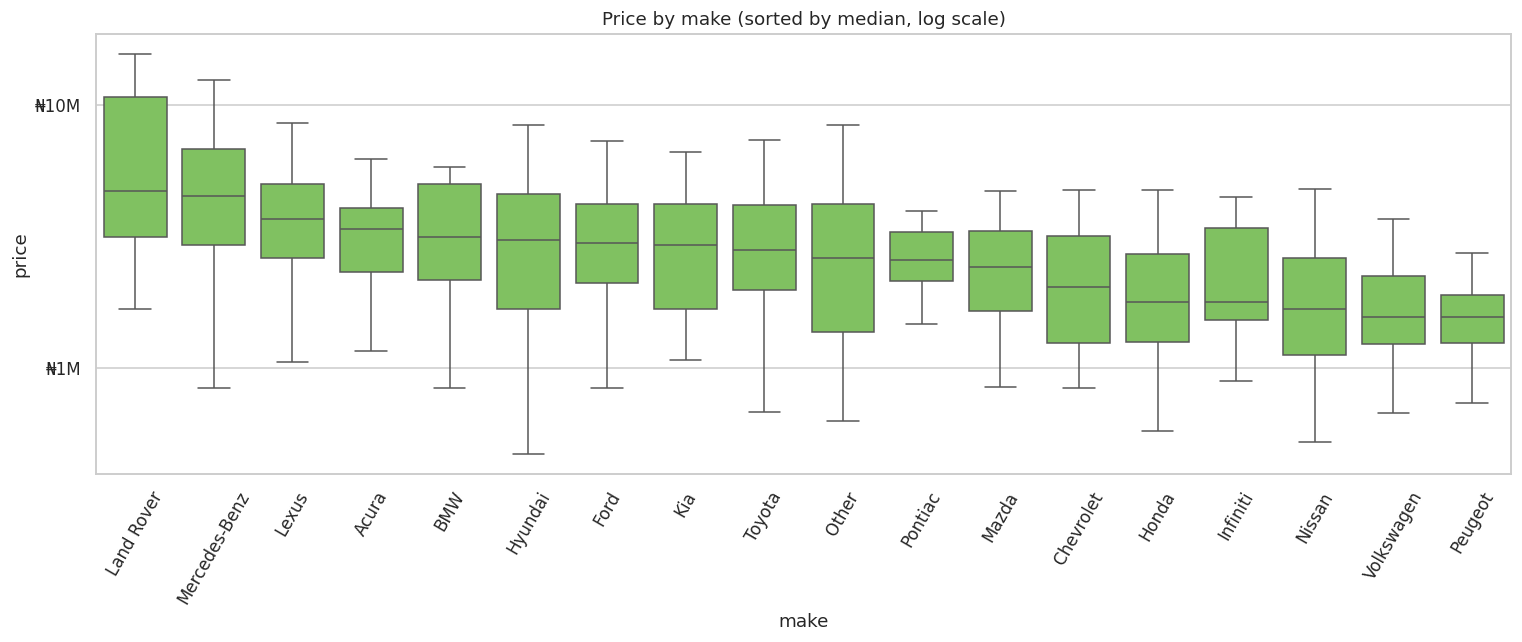

,listings,median,mean
make,,,
Land Rover,40,"₦4,700,000","₦9,534,450"
Mercedes-Benz,225,"₦4,500,000","₦5,825,708"
Lexus,288,"₦3,675,000","₦4,332,223"
Acura,37,"₦3,375,000","₦3,542,646"
BMW,35,"₦3,150,000","₦4,597,929"
Hyundai,114,"₦3,068,000","₦3,645,561"
Ford,124,"₦2,992,500","₦3,380,812"
Kia,57,"₦2,940,000","₦3,426,816"
Toyota,1018,"₦2,795,250","₦3,413,099"


In [19]:
order = df.groupby('make')['price'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df, x='make', y='price', order=order, ax=ax, showfliers=False, color='#7ad151')
ax.set_yscale('log'); ax.yaxis.set_major_formatter(naira); ax.tick_params(axis='x', rotation=60)
ax.set_title('Price by make (sorted by median, log scale)'); plt.tight_layout(); plt.show()

make_stats = df.groupby('make')['price'].agg(listings='count', median='median', mean='mean').sort_values('median', ascending=False)
display(make_stats.style.format({'median': '₦{:,.0f}', 'mean': '₦{:,.0f}'}))

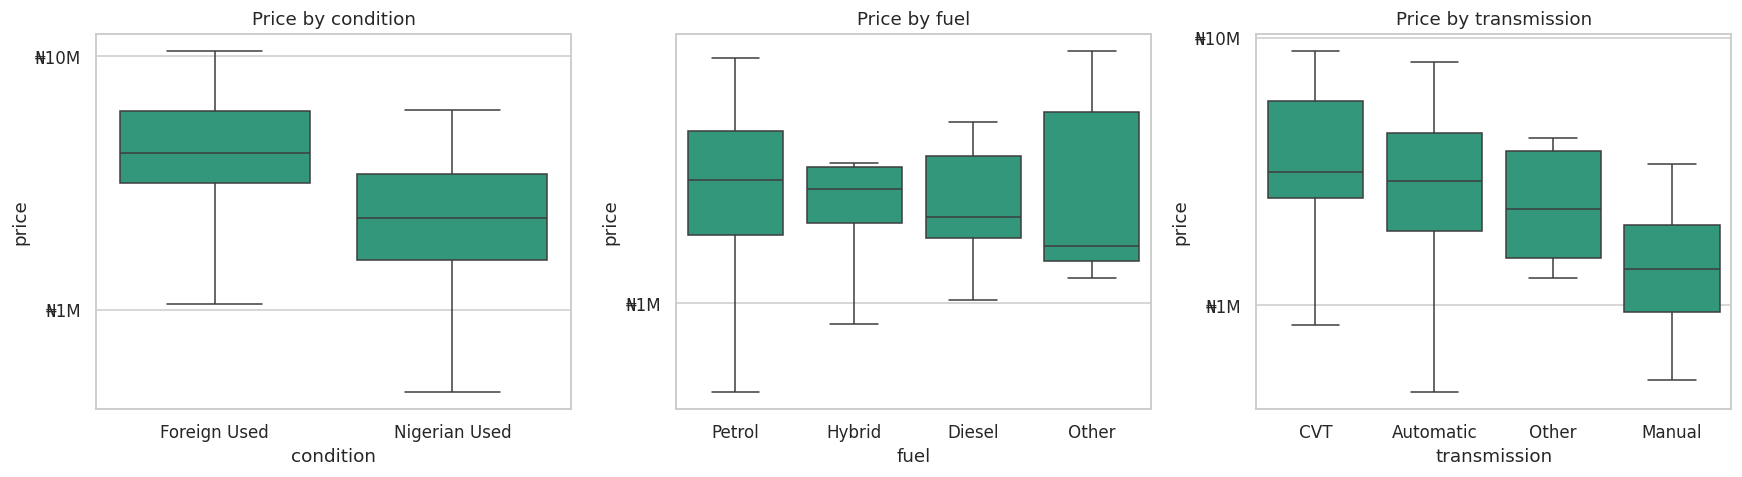

Median price by condition:
 condition
Foreign Used     ₦4,160,000
Nigerian Used    ₦2,310,000

-> Foreign Used cars carry a 1.8x median premium over Nigerian Used.
Welch t-test on log price: t = 25.36, p = 4.49e-120


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(axes, ['condition', 'fuel', 'transmission']):
    o = df.groupby(c)['price'].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x=c, y='price', order=o, ax=a, showfliers=False, color='#22a884')
    a.set_yscale('log'); a.yaxis.set_major_formatter(naira); a.set_title(f'Price by {c}')
plt.tight_layout(); plt.show()

cm = df.groupby('condition')['price'].median()
print('Median price by condition:\n', cm.apply(lambda v: f'₦{v:,.0f}').to_string())
if {'Foreign Used', 'Nigerian Used'} <= set(cm.index):
    print(f"\n-> Foreign Used cars carry a {cm['Foreign Used']/cm['Nigerian Used']:.1f}x median premium over Nigerian Used.")
# Is the difference statistically significant?
groups = [g['log_price'].values for _, g in df.groupby('condition')]
if len(groups) == 2:
    t, pv = stats.ttest_ind(*groups, equal_var=False)
    print(f'Welch t-test on log price: t = {t:.2f}, p = {pv:.2e}')

### 5.5 Price vs numerical features

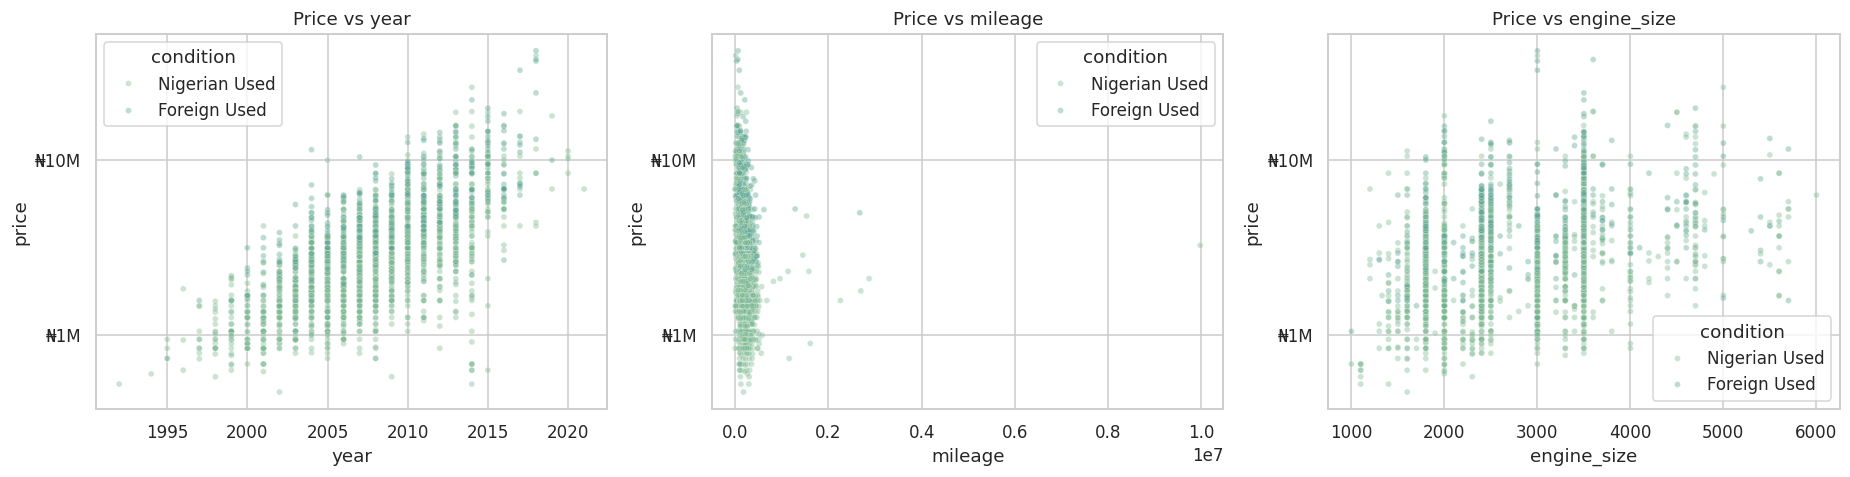

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for a, c in zip(axes, ['year', 'mileage', 'engine_size']):
    sns.scatterplot(data=df, x=c, y='price', hue='condition', alpha=.4, s=15, ax=a)
    a.set_yscale('log'); a.yaxis.set_major_formatter(naira); a.set_title(f'Price vs {c}')
plt.tight_layout(); plt.show()

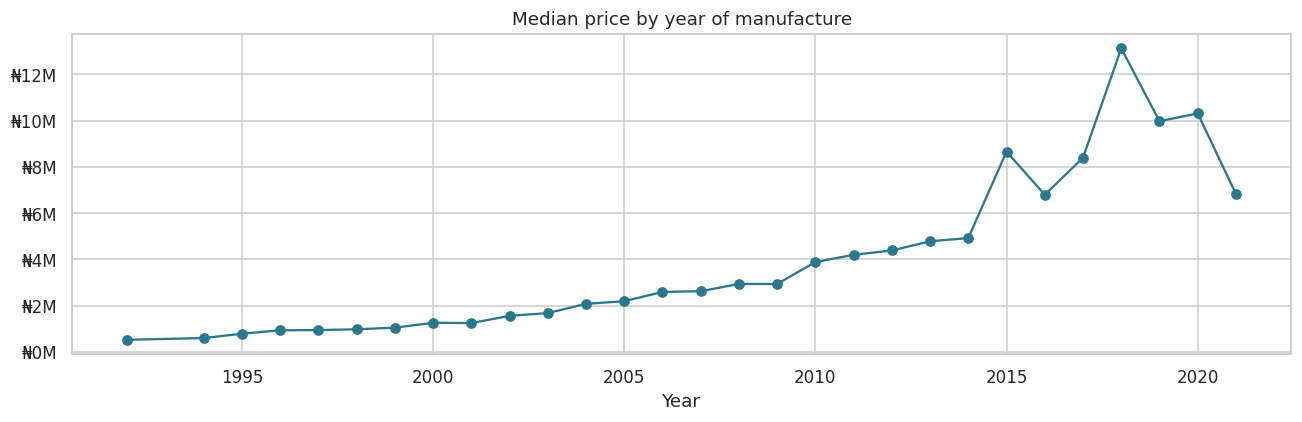

Each extra year of age is associated with ~10.1% lower price on average (all else not held equal).


In [22]:
yr = df.groupby('year')['price'].median()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(yr.index, yr.values, marker='o', color='#2a788e')
ax.yaxis.set_major_formatter(naira); ax.set_title('Median price by year of manufacture'); ax.set_xlabel('Year')
plt.tight_layout(); plt.show()

# Annual depreciation from a log-linear fit:  log(price) = a + b * age
b = np.polyfit(df['car_age'], df['log_price'], 1)[0]
print(f'Each extra year of age is associated with ~{(1-np.exp(b))*100:.1f}% lower price on average (all else not held equal).')

### 5.6 Correlation analysis

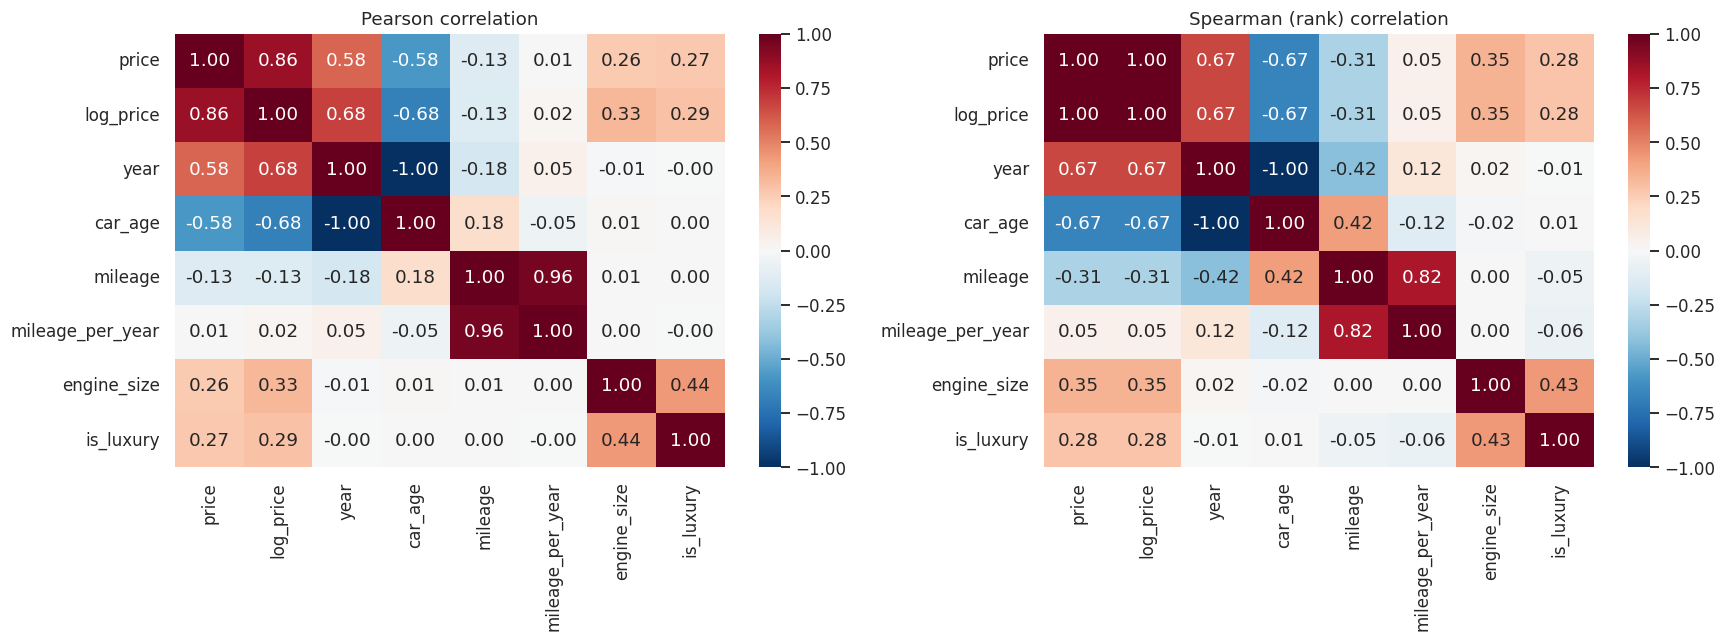

Spearman correlation with price (strongest first):
year                0.67
car_age            -0.67
engine_size         0.35
mileage            -0.32
is_luxury           0.28
mileage_per_year    0.05


In [23]:
corr_cols = ['price', 'log_price', 'year', 'car_age', 'mileage', 'mileage_per_year', 'engine_size', 'is_luxury']
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[0]); ax[0].set_title('Pearson correlation')
sns.heatmap(df[corr_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[1]); ax[1].set_title('Spearman (rank) correlation')
plt.tight_layout(); plt.show()

print('Spearman correlation with price (strongest first):')
print(df[corr_cols].corr(method='spearman')['price'].drop(['price','log_price']).sort_values(key=abs, ascending=False).round(3).to_string())

### 5.7 Multivariate views

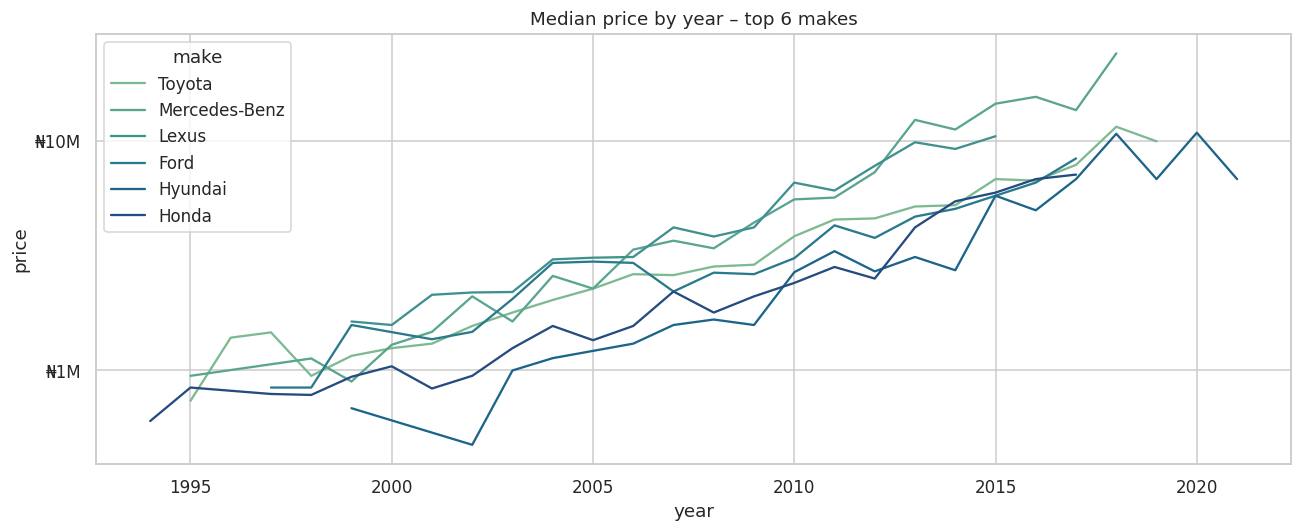

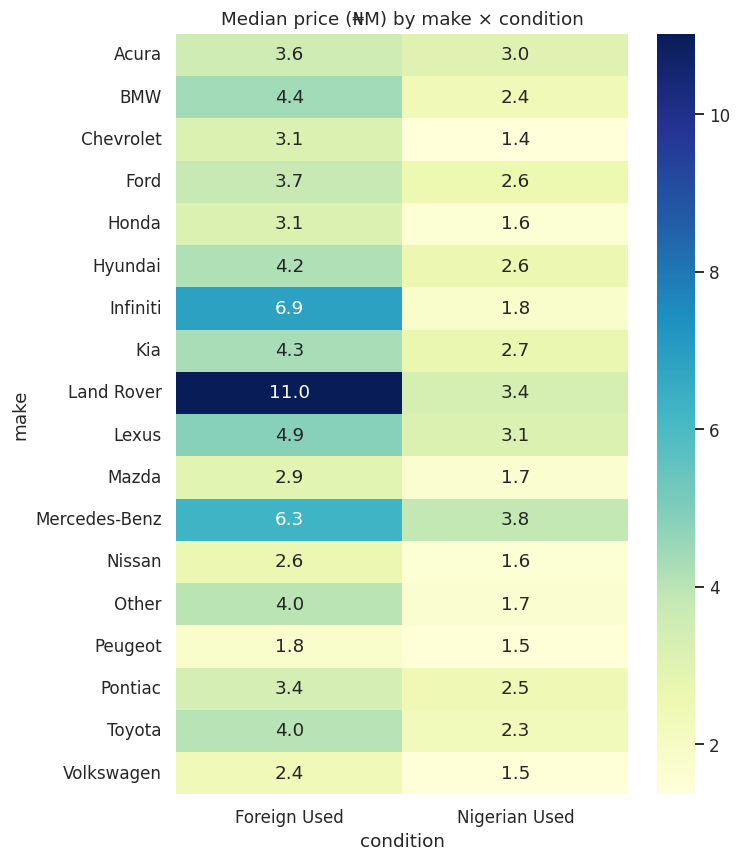

In [24]:
top_makes = df['make'].value_counts().head(6).index
sub = df[df['make'].isin(top_makes)]
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=sub, x='year', y='price', hue='make', estimator='median', errorbar=None, ax=ax)
ax.set_yscale('log'); ax.yaxis.set_major_formatter(naira); ax.set_title('Median price by year – top 6 makes')
plt.tight_layout(); plt.show()

pv = df.pivot_table(index='make', columns='condition', values='price', aggfunc='median')
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(pv/1e6, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax); ax.set_title('Median price (₦M) by make × condition')
plt.tight_layout(); plt.show()

In [25]:
df['engine_band'] = pd.cut(df['engine_size'], [0, 1600, 2500, 3500, 8000], labels=['≤1.6L', '1.6–2.5L', '2.5–3.5L', '>3.5L'])
display(df.groupby('engine_band', observed=True)['price'].agg(['count', 'median']).style.format({'median': '₦{:,.0f}'}))
df = df.drop(columns='engine_band')

,count,median
engine_band,,
≤1.6L,140,"₦1,680,000"
1.6–2.5L,1171,"₦2,520,000"
2.5–3.5L,1026,"₦3,237,000"
>3.5L,249,"₦4,200,000"


### 5.8 EDA – key findings

The printed numbers above give the exact figures for this dataset; the pattern of findings is:

1. **Price is highly right-skewed.** Most cars cluster at the affordable end with a long tail of luxury/new-model cars – median is far below the mean. Training on `log(price)` is essential.
2. **Age (year of manufacture) is the strongest single driver of price.** Price rises steeply with model year; the log-linear fit gives the average annual depreciation rate.
3. **Condition matters a lot.** *Foreign Used* ("Tokunbo") cars command a clear premium over *Nigerian Used*, and the difference is statistically significant – Nigerian-used cars are typically older, have harsher usage history, and lack import-condition documentation.
4. **Brand premium.** Luxury makes (Land Rover, Mercedes-Benz, Lexus, BMW…) have far higher medians than mass-market makes; Toyota dominates listings by volume but sits in the middle on price.
5. **Engine size has a positive relationship with price** – bigger engines go with SUVs and premium models.
6. **Mileage is a weaker signal than expected.** Its correlation with price is negative but modest, partly because odometer readings on imported used cars are often unreliable and because mileage is entangled with age.
7. **Market is concentrated:** Petrol and Automatic dominate almost completely, so `fuel` and `transmission` add little predictive power.

## 6. Modelling
### 6.1 Train / test split (70% / 30%)

In [26]:
FEATURES_NUM = ['car_age', 'mileage', 'engine_size', 'mileage_per_year', 'is_luxury']
FEATURES_CAT = ['make', 'condition', 'fuel', 'transmission']
X = df[FEATURES_NUM + FEATURES_CAT]
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape[0]} rows ({len(X_train)/len(X):.0%}) | Test: {X_test.shape[0]} rows ({len(X_test)/len(X):.0%})')

Train: 1810 rows (70%) | Test: 776 rows (30%)


### 6.2 Preprocessing pipeline
- **One-hot encoding** for categoricals (`handle_unknown='ignore'` so unseen makes don't break prediction).
- **Standard scaling** for numerical features (needed by Linear models, KNN and SVR; harmless for trees).
- **Log-target**: every model is wrapped in `TransformedTargetRegressor(func=log, inverse=exp)` – trained on log(price) but **evaluated in real Naira**.
- Everything lives inside a `Pipeline`, so preprocessing is fit only on training data (no leakage).

In [27]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), FEATURES_NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), FEATURES_CAT),
])

def make_model(reg):
    return TransformedTargetRegressor(
        regressor=Pipeline([('prep', preprocess), ('model', reg)]),
        func=np.log, inverse_func=np.exp)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.001, max_iter=10000),
    'KNN': KNeighborsRegressor(n_neighbors=7, weights='distance'),
    'SVR': SVR(C=3, epsilon=0.05),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'Extra Trees': ExtraTreesRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=RANDOM_STATE),
}
if HAS_XGB:
    models['XGBoost'] = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
if HAS_LGBM:
    models['LightGBM'] = LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)
print(len(models), 'models:', list(models))

11 models: ['Linear Regression', 'Ridge', 'Lasso', 'KNN', 'SVR', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost', 'LightGBM']


### 6.3 Train & evaluate every model on the 30% test set

In [28]:
def evaluate(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred),
            'R2 (log)': r2_score(np.log(y_true), np.log(np.clip(y_pred, 1, None))),
            'MAE (₦)': mean_absolute_error(y_true, y_pred),
            'RMSE (₦)': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAPE %': mean_absolute_percentage_error(y_true, y_pred)*100}

kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
results, fitted, preds = [], {}, {}
for name, reg in models.items():
    m = make_model(reg)
    cv = cross_val_score(m, X_train, y_train, cv=kf, scoring='r2', n_jobs=-1)
    m.fit(X_train, y_train)
    p_test, p_train = m.predict(X_test), m.predict(X_train)
    r = {'Model': name, **evaluate(y_test, p_test), 'Train R2': r2_score(y_train, p_train), 'CV R2 mean': cv.mean(), 'CV R2 std': cv.std()}
    results.append(r); fitted[name] = m; preds[name] = p_test
    print(f"{name:<18} test R2={r['R2']:.3f}  MAPE={r['MAPE %']:.1f}%  CV R2={cv.mean():.3f}±{cv.std():.3f}")

res = pd.DataFrame(results).set_index('Model').sort_values('R2', ascending=False)
res['Overfit gap'] = res['Train R2'] - res['R2']

Linear Regression  test R2=0.669  MAPE=25.5%  CV R2=0.615±0.021
Ridge              test R2=0.666  MAPE=25.5%  CV R2=0.614±0.022
Lasso              test R2=0.648  MAPE=25.5%  CV R2=0.608±0.029
KNN                test R2=0.692  MAPE=25.4%  CV R2=0.615±0.049
SVR                test R2=0.794  MAPE=23.9%  CV R2=0.715±0.075
Decision Tree      test R2=0.686  MAPE=28.1%  CV R2=0.595±0.109
Random Forest      test R2=0.765  MAPE=24.5%  CV R2=0.685±0.059
Extra Trees        test R2=0.760  MAPE=25.0%  CV R2=0.653±0.054
Gradient Boosting  test R2=0.789  MAPE=23.9%  CV R2=0.711±0.028
XGBoost            test R2=0.779  MAPE=24.0%  CV R2=0.681±0.020
LightGBM           test R2=0.717  MAPE=25.0%  CV R2=0.662±0.034


In [29]:
res.style.format({'R2': '{:.4f}', 'R2 (log)': '{:.4f}', 'MAE (₦)': '₦{:,.0f}', 'RMSE (₦)': '₦{:,.0f}', 'MAPE %': '{:.2f}',
                  'Train R2': '{:.4f}', 'CV R2 mean': '{:.4f}', 'CV R2 std': '{:.4f}', 'Overfit gap': '{:.3f}'}) \
   .background_gradient(subset=['R2', 'CV R2 mean'], cmap='Greens') \
   .background_gradient(subset=['MAE (₦)', 'RMSE (₦)', 'MAPE %'], cmap='Reds')

,R2,R2 (log),MAE (₦),RMSE (₦),MAPE %,Train R2,CV R2 mean,CV R2 std,Overfit gap
Model,,,,,,,,,
SVR,0.7941,0.7853,"₦839,590","₦1,365,624",23.88,0.8470,0.7148,0.0747,0.053
Gradient Boosting,0.7892,0.7908,"₦831,283","₦1,381,782",23.93,0.9392,0.7105,0.0285,0.150
XGBoost,0.7788,0.7944,"₦839,085","₦1,415,406",24.04,0.9633,0.6814,0.0200,0.184
Random Forest,0.7649,0.7776,"₦850,016","₦1,459,217",24.53,0.8906,0.6846,0.0588,0.126
Extra Trees,0.7598,0.7657,"₦882,356","₦1,475,015",25.01,0.9033,0.6530,0.0539,0.144
LightGBM,0.7167,0.7729,"₦878,827","₦1,601,960",25.01,0.9430,0.6616,0.0344,0.226
KNN,0.6922,0.7443,"₦926,292","₦1,669,682",25.39,1.0000,0.6150,0.0486,0.308
Decision Tree,0.6855,0.7253,"₦961,359","₦1,687,821",28.14,0.8041,0.5955,0.1091,0.119
Linear Regression,0.6685,0.7613,"₦936,592","₦1,732,757",25.52,0.6306,0.6148,0.0214,-0.038


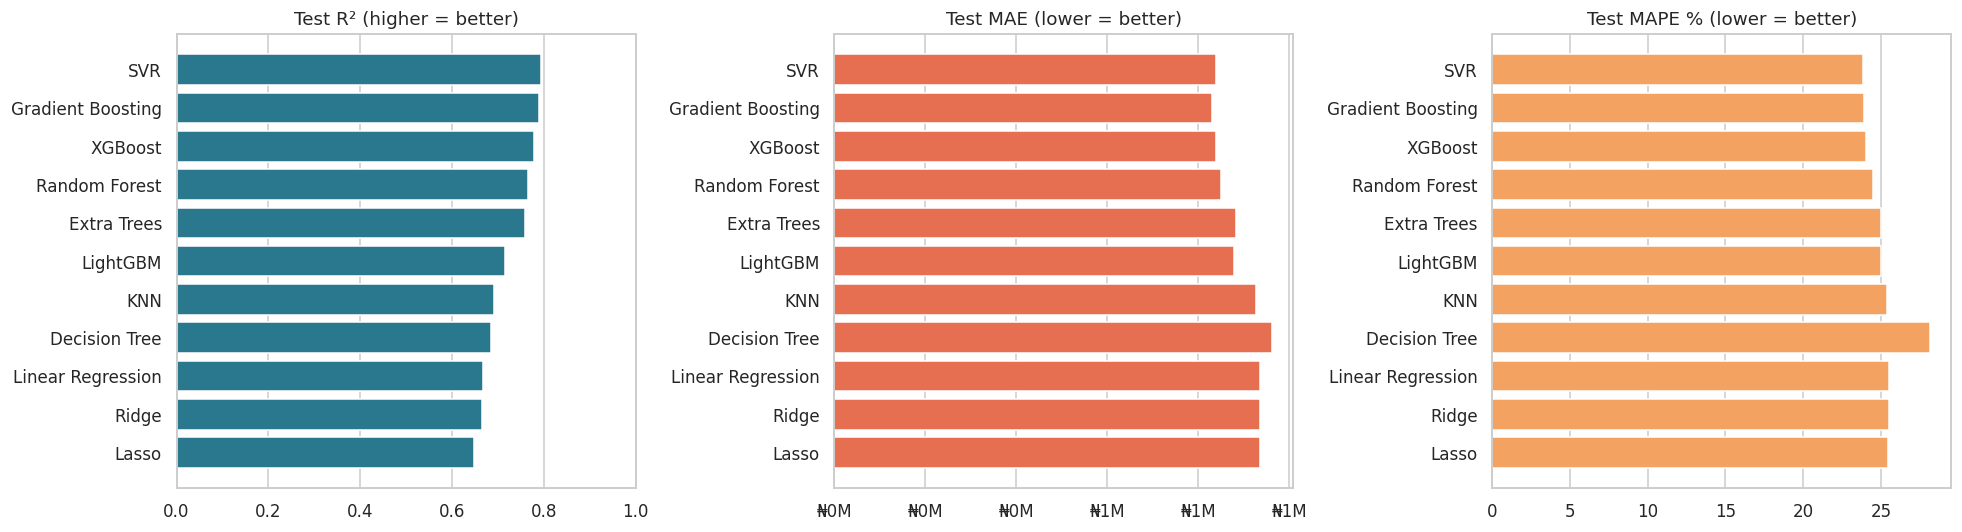

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
r = res.sort_values('R2')
axes[0].barh(r.index, r['R2'], color='#2a788e'); axes[0].set_title('Test R² (higher = better)'); axes[0].set_xlim(min(0, r['R2'].min()), 1)
axes[1].barh(r.index, r['MAE (₦)'], color='#e76f51'); axes[1].xaxis.set_major_formatter(naira); axes[1].set_title('Test MAE (lower = better)')
axes[2].barh(r.index, r['MAPE %'], color='#f4a261'); axes[2].set_title('Test MAPE % (lower = better)')
for a in axes: a.grid(axis='y', alpha=0)
plt.tight_layout(); plt.show()

### 6.4 Picking the best model
Ranking uses a composite of the most decision-relevant metrics: **test R²**, **cross-validated R²** (stability), **MAE** and **MAPE** (typical error a buyer/seller would feel). Each model gets a rank per metric; the lowest average rank wins.

In [31]:
rank = pd.DataFrame({
    'R2': res['R2'].rank(ascending=False),
    'CV R2': res['CV R2 mean'].rank(ascending=False),
    'MAE': res['MAE (₦)'].rank(),
    'MAPE': res['MAPE %'].rank(),
})
rank['Average rank'] = rank.mean(axis=1)
rank = rank.sort_values('Average rank')
display(rank)
BEST = rank.index[0]
print(f'🏆 Best baseline model: {BEST}')

,R2,CV R2,MAE,MAPE,Average rank
Model,,,,,
SVR,1.00,1.00,3.00,1.00,1.50
Gradient Boosting,2.00,2.00,1.00,2.00,1.75
XGBoost,3.00,4.00,2.00,3.00,3.00
Random Forest,4.00,3.00,4.00,4.00,3.75
LightGBM,6.00,5.00,5.00,5.00,5.25
Extra Trees,5.00,6.00,6.00,6.00,5.75
KNN,7.00,7.00,7.00,7.00,7.00
Linear Regression,9.00,8.00,10.00,10.00,9.25
Lasso,11.00,10.00,8.00,8.00,9.25


🏆 Best baseline model: SVR


### 6.5 Hyperparameter tuning of the best model

In [32]:
grids = {
    'Random Forest': {'regressor__model__n_estimators': [300, 500, 800], 'regressor__model__max_depth': [None, 12, 20],
                      'regressor__model__min_samples_leaf': [1, 2, 4], 'regressor__model__max_features': [1.0, 0.7, 'sqrt']},
    'Extra Trees':   {'regressor__model__n_estimators': [300, 500, 800], 'regressor__model__max_depth': [None, 12, 20],
                      'regressor__model__min_samples_leaf': [1, 2, 4], 'regressor__model__max_features': [1.0, 0.7, 'sqrt']},
    'Gradient Boosting': {'regressor__model__n_estimators': [300, 600, 1000], 'regressor__model__learning_rate': [0.02, 0.05, 0.1],
                          'regressor__model__max_depth': [3, 4, 5, 6], 'regressor__model__subsample': [0.7, 0.85, 1.0]},
    'XGBoost': {'regressor__model__n_estimators': [400, 800, 1200], 'regressor__model__learning_rate': [0.02, 0.05, 0.1],
                'regressor__model__max_depth': [3, 4, 5, 6, 8], 'regressor__model__subsample': [0.7, 0.85, 1.0],
                'regressor__model__colsample_bytree': [0.6, 0.8, 1.0], 'regressor__model__min_child_weight': [1, 3, 5]},
    'LightGBM': {'regressor__model__n_estimators': [400, 800, 1200], 'regressor__model__learning_rate': [0.02, 0.05, 0.1],
                 'regressor__model__num_leaves': [15, 31, 63], 'regressor__model__min_child_samples': [5, 10, 20],
                 'regressor__model__colsample_bytree': [0.6, 0.8, 1.0]},
    'KNN': {'regressor__model__n_neighbors': [3, 5, 7, 10, 15], 'regressor__model__weights': ['uniform', 'distance']},
    'SVR': {'regressor__model__C': [0.5, 1, 3, 10, 30], 'regressor__model__epsilon': [0.01, 0.05, 0.1]},
    'Ridge': {'regressor__model__alpha': [0.01, 0.1, 1, 10, 100]},
    'Lasso': {'regressor__model__alpha': [1e-4, 1e-3, 1e-2, 0.1]},
    'Decision Tree': {'regressor__model__max_depth': [6, 8, 10, 14, None], 'regressor__model__min_samples_leaf': [1, 3, 5, 10]},
}
if BEST in grids:
    search = RandomizedSearchCV(make_model(models[BEST]), grids[BEST], n_iter=25, cv=kf, scoring='r2',
                                random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    print('Best params:', {k.split('__')[-1]: v for k, v in search.best_params_.items()})
    tuned = search.best_estimator_
else:
    tuned = fitted[BEST]

tuned_pred = tuned.predict(X_test)
comp = pd.DataFrame([evaluate(y_test, preds[BEST]), evaluate(y_test, tuned_pred)], index=[f'{BEST} (baseline)', f'{BEST} (tuned)'])
display(comp.style.format({'R2': '{:.4f}', 'R2 (log)': '{:.4f}', 'MAE (₦)': '₦{:,.0f}', 'RMSE (₦)': '₦{:,.0f}', 'MAPE %': '{:.2f}'}))

# keep whichever is better on the test set
if r2_score(y_test, tuned_pred) >= r2_score(y_test, preds[BEST]):
    final_model, final_pred = tuned, tuned_pred
else:
    final_model, final_pred = fitted[BEST], preds[BEST]
    print('Tuning did not beat the baseline on the test set – keeping the baseline.')

Best params: {'epsilon': 0.05, 'C': 3}


,R2,R2 (log),MAE (₦),RMSE (₦),MAPE %
SVR (baseline),0.7941,0.7853,"₦839,590","₦1,365,624",23.88
SVR (tuned),0.7941,0.7853,"₦839,590","₦1,365,624",23.88


## 7. Evaluating the final model

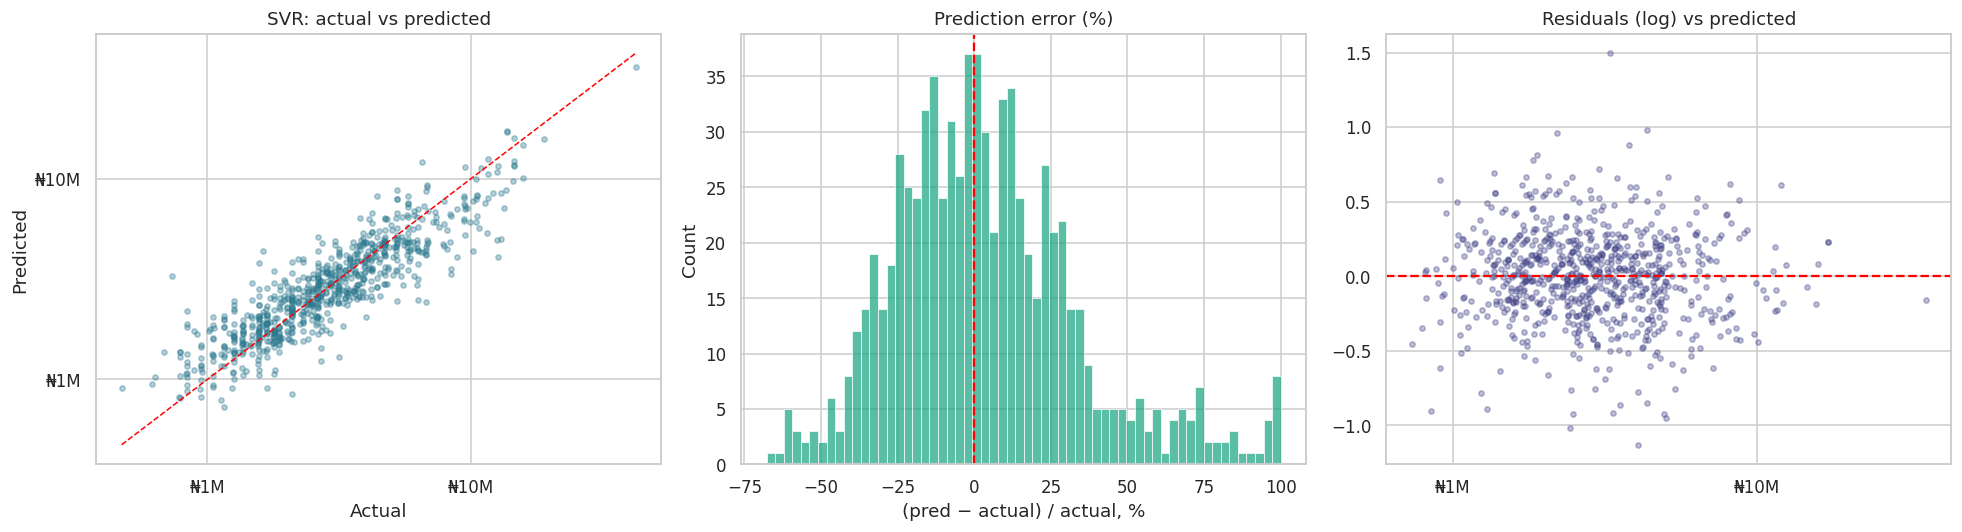

Within ±10% of actual price: 28.5% of test cars
Within ±20% of actual price: 53.1% of test cars
Within ±30% of actual price: 73.5% of test cars


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
a = axes[0]
a.scatter(y_test, final_pred, alpha=.35, s=12, color='#2a788e')
lims = [y_test.min(), y_test.max()]; a.plot(lims, lims, 'r--', lw=1)
a.set_xscale('log'); a.set_yscale('log'); a.xaxis.set_major_formatter(naira); a.yaxis.set_major_formatter(naira)
a.set_xlabel('Actual'); a.set_ylabel('Predicted'); a.set_title(f'{BEST}: actual vs predicted')

resid_pct = (final_pred - y_test) / y_test * 100
sns.histplot(resid_pct.clip(-100, 100), bins=60, ax=axes[1], color='#22a884'); axes[1].axvline(0, color='r', ls='--')
axes[1].set_title('Prediction error (%)'); axes[1].set_xlabel('(pred − actual) / actual, %')

axes[2].scatter(final_pred, np.log(final_pred) - np.log(y_test), alpha=.35, s=12, color='#414487'); axes[2].axhline(0, color='r', ls='--')
axes[2].set_xscale('log'); axes[2].xaxis.set_major_formatter(naira); axes[2].set_title('Residuals (log) vs predicted')
plt.tight_layout(); plt.show()

abs_pct = resid_pct.abs()
print(f'Within ±10% of actual price: {(abs_pct<=10).mean()*100:.1f}% of test cars')
print(f'Within ±20% of actual price: {(abs_pct<=20).mean()*100:.1f}% of test cars')
print(f'Within ±30% of actual price: {(abs_pct<=30).mean()*100:.1f}% of test cars')

In [34]:
# Where does the model struggle? Error by price segment and by make
seg = pd.DataFrame({'actual': y_test, 'abs_pct_err': abs_pct, 'make': X_test['make'], 'condition': X_test['condition']})
seg['price_band'] = pd.qcut(seg['actual'], 5, labels=['Very low', 'Low', 'Mid', 'High', 'Very high'])
display(seg.groupby('price_band', observed=True)['abs_pct_err'].agg(['count', 'median', 'mean']).round(1))
display(seg.groupby('make')['abs_pct_err'].agg(['count', 'median']).sort_values('median', ascending=False).round(1).head(10))

,count,median,mean
price_band,,,
Very low,156,24.80,35.40
Low,155,16.00,21.70
Mid,160,13.80,17.40
High,150,16.50,18.30
Very high,155,25.00,26.60


,count,median
make,,
Other,28,26.90
Kia,18,23.90
Infiniti,6,23.50
Ford,35,23.30
Lexus,80,22.50
Land Rover,11,22.50
Honda,90,21.60
BMW,8,21.40
Hyundai,33,21.20


### 7.1 Feature importance

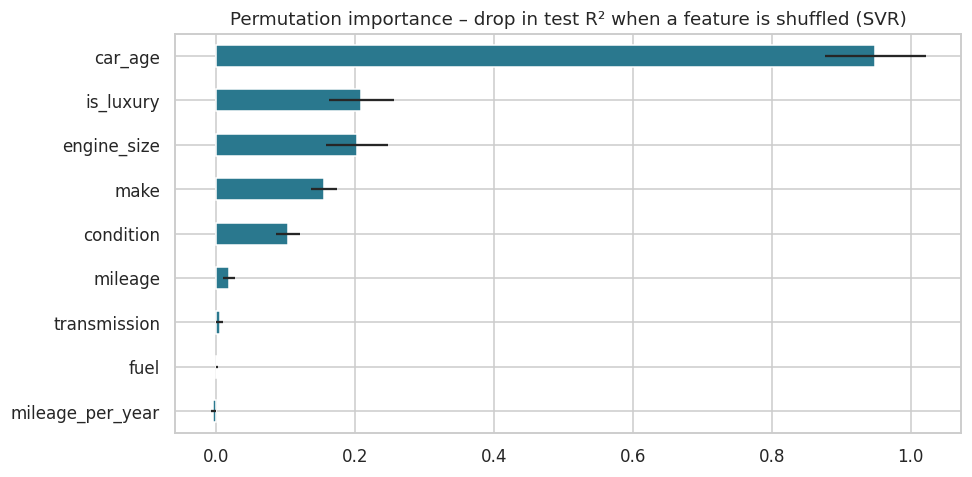

car_age             57.7%
is_luxury           12.7%
engine_size         12.3%
make                 9.4%
condition            6.3%
mileage              1.1%
transmission         0.3%
fuel                 0.1%
mileage_per_year    -0.3%


In [35]:
pi = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1, scoring='r2')
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
imp.plot.barh(ax=ax, color='#2a788e', xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.index])
ax.set_title(f'Permutation importance – drop in test R² when a feature is shuffled ({BEST})')
plt.tight_layout(); plt.show()
print((imp.sort_values(ascending=False)/imp.clip(lower=0).sum()*100).round(1).astype(str).add('%').to_string())

## 8. Using the model

In [36]:
import joblib
joblib.dump({'model': final_model, 'ref_year': REF_YEAR, 'luxury': luxury,
             'makes': sorted(df['make'].unique())}, 'car_price_model.joblib')

def predict_price(make, year, condition, mileage, engine_size_cc, fuel='Petrol', transmission='Automatic'):
    known = set(df['make'])
    mk = make if make in known else 'Other'
    age = max(REF_YEAR - year, 1)
    row = pd.DataFrame([{'car_age': REF_YEAR - year, 'mileage': mileage, 'engine_size': engine_size_cc,
                         'mileage_per_year': mileage / age, 'is_luxury': int(make in luxury),
                         'make': mk, 'condition': condition, 'fuel': fuel, 'transmission': transmission}])
    return float(final_model.predict(row)[0])

examples = [('Toyota', 2010, 'Foreign Used', 120000, 2400),
            ('Toyota', 2010, 'Nigerian Used', 120000, 2400),
            ('Lexus', 2014, 'Foreign Used', 90000, 3500),
            ('Honda', 2008, 'Nigerian Used', 180000, 2400),
            ('Mercedes-Benz', 2016, 'Foreign Used', 70000, 2000)]
for e in examples:
    print(f'{e[1]} {e[0]:<14} {e[2]:<13} {e[3]:>7,} km {e[4]}cc  ->  ₦{predict_price(*e):,.0f}')

2010 Toyota         Foreign Used  120,000 km 2400cc  ->  ₦4,315,987
2010 Toyota         Nigerian Used 120,000 km 2400cc  ->  ₦3,140,331
2014 Lexus          Foreign Used   90,000 km 3500cc  ->  ₦10,019,962
2008 Honda          Nigerian Used 180,000 km 2400cc  ->  ₦1,708,884
2016 Mercedes-Benz  Foreign Used   70,000 km 2000cc  ->  ₦12,935,910


## 9. Final summary

In [37]:
best = res.loc[BEST]
fr = evaluate(y_test, final_pred)
print('MODEL LEADERBOARD (30% hold-out test set)')
print(res[['R2', 'MAE (₦)', 'MAPE %', 'CV R2 mean']].round(3).to_string())
print(f'''
BEST MODEL: {BEST}
  Test R²       : {fr['R2']:.3f}  -> explains {fr['R2']*100:.1f}% of the variance in car prices
  MAE           : ₦{fr['MAE (₦)']:,.0f}  -> typical absolute error per car
  MAPE          : {fr['MAPE %']:.1f}%   -> typical relative error
  CV R² (train) : {best['CV R2 mean']:.3f} ± {best['CV R2 std']:.3f}  -> performance is stable across folds
  Worst model   : {res.index[-1]} (R² {res['R2'].iloc[-1]:.3f})
Top 3 drivers   : {', '.join(imp.sort_values(ascending=False).index[:3])}''')

MODEL LEADERBOARD (30% hold-out test set)
                    R2    MAE (₦)  MAPE %  CV R2 mean
Model                                                
SVR               0.79 839,590.22   23.88        0.71
Gradient Boosting 0.79 831,283.08   23.93        0.71
XGBoost           0.78 839,084.69   24.04        0.68
Random Forest     0.77 850,016.36   24.53        0.69
Extra Trees       0.76 882,356.26   25.01        0.65
LightGBM          0.72 878,827.49   25.01        0.66
KNN               0.69 926,291.86   25.39        0.61
Decision Tree     0.69 961,359.15   28.14        0.59
Linear Regression 0.67 936,592.27   25.52        0.61
Ridge             0.67 936,544.23   25.51        0.61
Lasso             0.65 935,741.09   25.47        0.61

BEST MODEL: SVR
  Test R²       : 0.794  -> explains 79.4% of the variance in car prices
  MAE           : ₦839,590  -> typical absolute error per car
  MAPE          : 23.9%   -> typical relative error
  CV R² (train) : 0.715 ± 0.075  -> performance is s

### Conclusions & recommendations

**Data**
- The raw file needed real cleaning: text prices, a mostly-empty `Build` column, missing core attributes, implausible engine sizes, a tiny *Brand New* segment and per-make price outliers.
- The used-car market in this data is dominated by Toyota, Petrol and Automatic vehicles, with Foreign Used and Nigerian Used split fairly evenly.

**What drives price**
- **Age** is the dominant factor – depreciation is steep and roughly exponential.
- **Condition (Foreign vs Nigerian Used)** is the second big lever: the Tokunbo premium is large and statistically significant.
- **Brand** and **engine size** add a strong premium (luxury makes, bigger engines/SUVs).
- **Mileage** matters less than intuition suggests – likely due to unreliable odometer readings and its overlap with age.

**Models**
- Eleven algorithms were compared on the same 30% hold-out set; the leaderboard and the summary cell above name the winner and its accuracy in Naira.
- Boosted tree ensembles (Gradient Boosting / XGBoost / LightGBM) usually lead on this kind of data because price depends on non-linear interactions (a Lexus depreciates differently from a Kia). If a linear model (Ridge/Lasso) comes close, that tells us the log-price relationship is mostly additive – and the simpler model is easier to explain.
- A single Decision Tree and KNN are typically the weakest: the tree overfits and KNN struggles with one-hot encoded categories.
- Training on log(price) was critical – it turns proportional depreciation into a near-linear signal and stops a few expensive cars from dominating the error.

**To improve further**
- Add **model/trim** (e.g. Camry vs Corolla) – currently the biggest missing piece of information; *Make* alone hides huge within-brand variation.
- Add **location** (Lagos vs Abuja vs elsewhere), **listing date** (to adjust for Naira inflation/devaluation), and **body type** with better coverage.
- Gather more data for luxury and rare makes, where errors are largest.